# Clase 3 — La cueva con mapa: MDP y ecuaciones de Bellman

**RL a ciegas · vía profunda** — basado en CS234 (Brunskill), *Lecture 2: Making Sequences of Good Decisions Given a Model of the World*, y Sutton & Barto cap. 3–4.

En la clase 2 el agente estaba a ciegas. Hoy hacemos trampa: **le damos el mapa**. Si conocemos exactamente cómo responde el mundo a cada acción, ¿cuál es la mejor forma de llegar a la salida?

Hoy vamos a ver:

1. La cueva como **proceso de decisión de Markov** (*Markov Decision Process*, MDP): estados, acciones, $P$ y $R$.
2. **Retorno** y **descuento** $\gamma$.
3. **Evaluación de una política** (*policy evaluation*): ¿cuánto vale caminar al azar?
4. **Iteración de valores** (*value iteration*): la mejor política.
5. **Iteración de políticas** (*policy iteration*): otra forma de llegar a lo mismo.
6. Qué pasa si cambiamos $\gamma$, el costo por paso y el piso (resbaloso o no).

### Preparación

La primera celda escribe el entorno `cave_env.py` (así el notebook funciona solo, en Colab o local). La segunda importa lo necesario.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 3 (con modelo): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax


Overwriting cave_env.py


In [2]:
from cave_env import CaveEnv, ACTION_NAMES
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.dpi"] = 100

### Herramientas

La celda siguiente define las funciones que usamos en la clase (evaluación de políticas, iteración de valores, iteración de políticas y algunos dibujos; `plot_cave` es el mismo `env.plot` de siempre, con las flechas remarcadas). **No hace falta leerla**: está plegada. Las celdas de la clase solo llaman a estas funciones y miran los resultados.

In [3]:
# @title Herramientas (plegada)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe

def random_policy(env):
    """Política aleatoria: pi[s, a] = 1/4 para toda acción."""
    return np.full((env.nS, env.nA), 1.0 / env.nA)


def bellman_backup(env, V, gamma):
    """Q[s, a] = R[s, a] + gamma * sum_s' P[s, a, s'] V[s']."""
    return env.R + gamma * env.P @ V


def policy_evaluation(env, pi, gamma, tol=1e-8, max_iter=100_000):
    """Evaluación iterativa (Bellman de expectativa). Devuelve V y la historia de V_k."""
    V = np.zeros(env.nS)
    history = [V.copy()]
    for _ in range(max_iter):
        V_new = (pi * bellman_backup(env, V, gamma)).sum(axis=1)
        history.append(V_new.copy())
        if np.max(np.abs(V_new - V)) < tol:
            break
        V = V_new
    return V_new, history


def value_iteration(env, gamma, tol=1e-10, max_iter=100_000):
    """Iteración de valores (Bellman de optimalidad). Devuelve V*, política greedy e historia."""
    V = np.zeros(env.nS)
    history = [V.copy()]
    for _ in range(max_iter):
        Q = bellman_backup(env, V, gamma)
        V_new = Q.max(axis=1)
        history.append(V_new.copy())
        if np.max(np.abs(V_new - V)) < tol:
            break
        V = V_new
    policy = bellman_backup(env, V_new, gamma).argmax(axis=1)
    return V_new, policy, history


def exact_evaluation(env, policy, gamma):
    """V^pi resolviendo el sistema lineal (I - gamma P_pi) V = R_pi (política determinista)."""
    idx = np.arange(env.nS)
    P_pi, R_pi = env.P[idx, policy], env.R[idx, policy]
    if gamma < 1:
        return np.linalg.solve(np.eye(env.nS) - gamma * P_pi, R_pi)
    return policy_evaluation(env, np.eye(env.nA)[policy], gamma)[0]


def policy_iteration(env, gamma, policy0=None):
    """Iteración de políticas: evaluar -> mejorar, hasta que la política no cambia."""
    policy = np.zeros(env.nS, dtype=int) if policy0 is None else policy0.copy()
    policies = [policy.copy()]
    while True:
        V = exact_evaluation(env, policy, gamma)
        Q = bellman_backup(env, V, gamma)
        new = Q.argmax(axis=1)
        tie = np.isclose(Q[np.arange(env.nS), policy], Q.max(axis=1))
        new[tie] = policy[tie]                   # si empata, no cambiamos (evita oscilar)
        if np.array_equal(new, policy):
            return V, policy, policies
        policy = new
        policies.append(policy.copy())


def optimal_actions(env, gamma):
    """Máscara [s, a]: True si la acción a es óptima en s (puede haber empates)."""
    V, _, _ = value_iteration(env, gamma)
    Q = bellman_backup(env, V, gamma)
    return np.isclose(Q, Q.max(axis=1, keepdims=True), atol=1e-9)


def frac_optimal(env, policy, opt_mask):
    """Fracción de casillas (sin contar la salida) donde la flecha es óptima."""
    ss = [s for s in range(env.nS) if s != env.goal]
    return np.mean([opt_mask[s, policy[s]] for s in ss])


def run_policy(env, policy, max_steps=100, seed=0):
    """Juega una vez siguiendo la política desde S. Devuelve la lista de casillas visitadas."""
    env.rng = np.random.default_rng(seed)
    s = env.reset()
    path = [s]
    for _ in range(max_steps):
        s, r, done, info = env.step(int(policy[s]))
        path.append(s)
        if info["reached_goal"]:
            break
    return path


def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None,
              cmap="magma", clim=None):
    """env.plot con dos retoques: flechas con borde negro (se leen sobre cualquier color)
    y escala de color calculada sin la salida (que se pinta verde igual)."""
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None:
        if clim is None:
            v = np.asarray(values)[np.arange(env.nS) != env.goal]
            clim = (v.min(), v.max())
        lo, hi = clim
        if hi - lo < 1e-12:
            lo = hi - 1.0
        ax.images[-1].set_clim(lo, hi)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    return ax


def plot_row(env, values_list, titles, policies=None, paths=None, shared=True, cmap="magma", size=4.3):
    """Varios mapas de la cueva lado a lado (misma escala de color si shared=True)."""
    n = len(values_list)
    fig, axes = plt.subplots(1, n, figsize=(size * n, size * env.H / env.W + 0.6))
    axes = np.atleast_1d(axes)
    notgoal = np.arange(env.nS) != env.goal
    clim = (min(np.min(v[notgoal]) for v in values_list), max(np.max(v[notgoal]) for v in values_list))
    for i, ax in enumerate(axes):
        plot_cave(env, values=values_list[i], ax=ax, title=titles[i], cmap=cmap,
                  policy=None if policies is None else policies[i],
                  path=None if paths is None else paths[i],
                  clim=clim if shared else None)
    plt.tight_layout()
    plt.show()


def show_transitions(env, s):
    """Tabla: desde la casilla s, para cada acción, adónde puedo terminar, con qué prob y qué recompensa."""
    r, c = env.free[s]
    print(f"Casilla s = {s}  (fila {r}, columna {c})")
    for a in range(env.nA):
        dest = [(env.free[s2], round(float(p), 2)) for s2, p in enumerate(env.P[s, a]) if p > 0]
        print(f"  acción {ACTION_NAMES[a]}:  P -> {dest}   R[s,a] = {env.R[s, a]:+.2f}")

## Paso 1 — La cueva como MDP

Un MDP es una tupla $(S, A, P, R, \gamma)$:

- $S$: estados → cada casilla libre de la cueva.
- $A$: acciones → ↑ → ↓ ←.
- $P(s' \mid s, a)$: el **modelo de transición** → adónde voy a parar si hago $a$ en $s$.
- $R(s, a)$: la **recompensa** esperada → +1 al entrar a la salida, 0 en otro caso.
- $\gamma$: el **factor de descuento** (lo vemos en el Paso 2).

Primero, miremos la cueva *con* el mapa (lo que el jugador nunca ve): gris = pared, verde = salida, S = inicio.

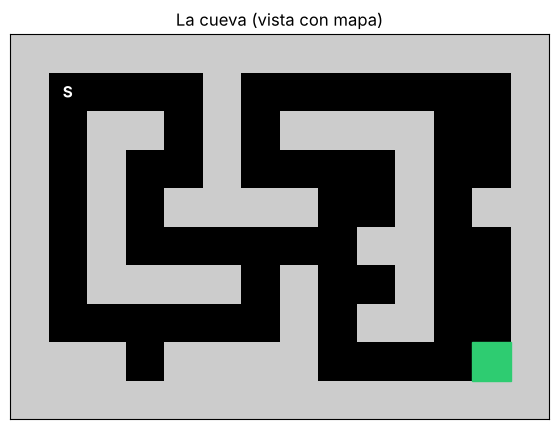

Estados (casillas libres): 60
Acciones: 4 ['↑', '→', '↓', '←']
P tiene forma (60, 4, 60)  y R tiene forma (60, 4)


In [4]:
env = CaveEnv()
env.plot(title="La cueva (vista con mapa)")
plt.show()
print("Estados (casillas libres):", env.nS)
print("Acciones:", env.nA, ACTION_NAMES)
print("P tiene forma", env.P.shape, " y R tiene forma", env.R.shape)

Ahora miremos $P$ y $R$ para dos casillas: el inicio **S** y la casilla justo a la izquierda de la salida.
En el inicio, ir ↑ o ← es chocar contra la pared: $P$ nos deja en el mismo lugar. Al lado de la salida, la acción → tiene $R = +1$.

In [5]:
show_transitions(env, env.start)
print()
left_of_goal = env.pos2s[(8, 11)]
show_transitions(env, left_of_goal)

Casilla s = 0  (fila 1, columna 1)
  acción ↑:  P -> [((1, 1), 1.0)]   R[s,a] = +0.00
  acción →:  P -> [((1, 2), 1.0)]   R[s,a] = +0.00
  acción ↓:  P -> [((2, 1), 1.0)]   R[s,a] = +0.00
  acción ←:  P -> [((1, 1), 1.0)]   R[s,a] = +0.00

Casilla s = 58  (fila 8, columna 11)
  acción ↑:  P -> [((7, 11), 1.0)]   R[s,a] = +0.00
  acción →:  P -> [((8, 12), 1.0)]   R[s,a] = +1.00
  acción ↓:  P -> [((8, 11), 1.0)]   R[s,a] = +0.00
  acción ←:  P -> [((8, 10), 1.0)]   R[s,a] = +0.00


$P$ también se puede **ver**. Dibujemos $P(s' \mid s{=}S, a{=}\downarrow)$ sobre la cueva: con piso normal toda la probabilidad cae en una casilla; con piso **resbaloso** (`slip=0.2`) el 20 % de las veces el agente se desvía a un costado (y si hay pared, choca y se queda).

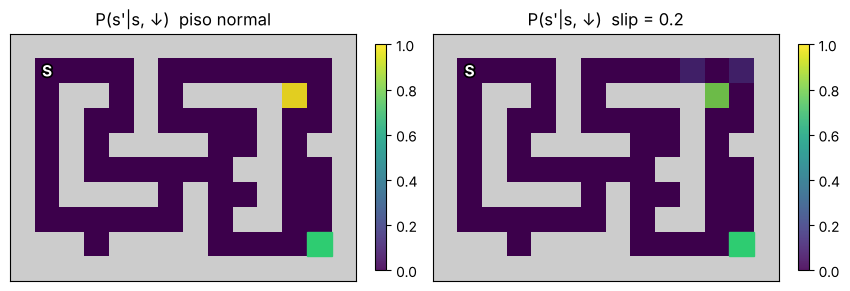

In [6]:
env_slip = CaveEnv(slip=0.2)
s, a = env.pos2s[(1, 11)], 2          # una casilla con espacio a los costados, acción ↓
plot_row(env, [env.P[s, a], env_slip.P[s, a]],
         [f"P(s'|s, ↓)  piso normal", f"P(s'|s, ↓)  slip = 0.2"], cmap="viridis")

## Paso 2 — Retorno y descuento $\gamma$

El agente no quiere la recompensa de *este* paso, sino la suma de todas las que vienen: el **retorno** (*return*). Con descuento, la recompensa que llega dentro de $t$ pasos pesa $\gamma^t$. Veamos ese peso para tres valores de $\gamma$.

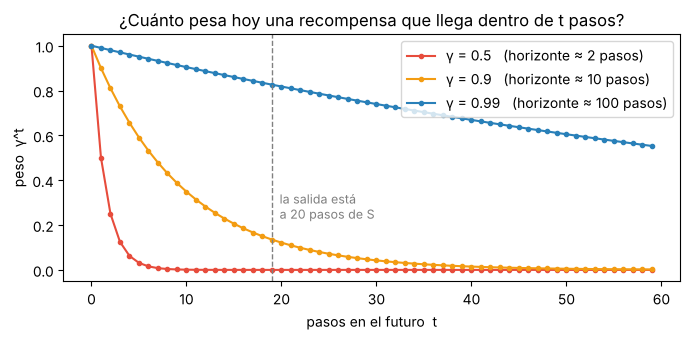

γ = 0.5:  la salida (a 20 pasos) vale hoy γ^19 = 0.000002
γ = 0.9:  la salida (a 20 pasos) vale hoy γ^19 = 0.135085
γ = 0.99:  la salida (a 20 pasos) vale hoy γ^19 = 0.826169


In [7]:
t = np.arange(0, 60)
fig, ax = plt.subplots(figsize=(7, 3.5))
for g, col in [(0.5, "#e74c3c"), (0.9, "#f39c12"), (0.99, "#2980b9")]:
    ax.plot(t, g ** t, "-o", ms=3, color=col, label=f"γ = {g}   (horizonte ≈ {1/(1-g):.0f} pasos)")
ax.axvline(19, color="gray", ls="--", lw=1)
ax.text(19.8, 0.35, "la salida está\na 20 pasos de S", color="gray", fontsize=9, va="top")
ax.set_xlabel("pasos en el futuro  t"); ax.set_ylabel("peso  γ^t")
ax.set_title("¿Cuánto pesa hoy una recompensa que llega dentro de t pasos?")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

for g in [0.5, 0.9, 0.99]:
    print(f"γ = {g}:  la salida (a 20 pasos) vale hoy γ^19 = {g**19:.6f}")

Ahora la ecuación:

$$G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots = \sum_{k=0}^{\infty} \gamma^k\, r_{t+k+1}$$

**Pregunta de Brunskill:** *¿un $\gamma$ grande hace que pesen más las recompensas inmediatas?*
Mirando la figura: **falso**. Con $\gamma = 0.5$ la curva se desploma en pocos pasos (agente *miope*: solo le importa lo inmediato). Con $\gamma = 0.99$ la curva casi no baja: el futuro lejano sigue pesando. Una regla útil: el horizonte efectivo es $\approx 1/(1-\gamma)$ pasos.

## Paso 3 — Evaluar una política: ¿cuánto vale caminar al azar?

Una **política** $\pi(a \mid s)$ dice qué hacer en cada casilla. El **valor** $V^\pi(s)$ es el retorno esperado si arranco en $s$ y sigo $\pi$.

Empezamos con la política más tonta: elegir cualquiera de las 4 direcciones al azar (es lo que hace un jugador perdido). El algoritmo arranca con $V = 0$ y repite una actualización sobre todas las casillas. Miremos qué pasa en las iteraciones 1, 5, 20 y al final (misma escala de color en los 4 paneles).

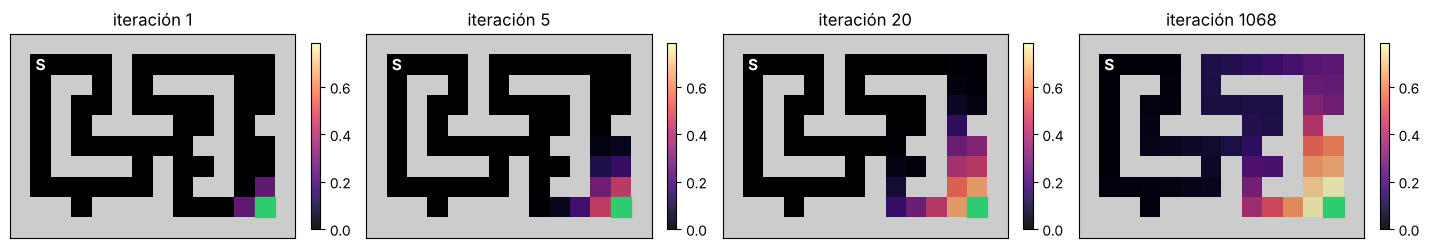

In [8]:
gamma = 0.99
pi_rand = random_policy(env)
V_rand, hist = policy_evaluation(env, pi_rand, gamma)

ks = [1, 5, 20, len(hist) - 1]
plot_row(env, [hist[k] for k in ks], [f"iteración {k}" for k in ks], size=3.6)

El valor **nace en la salida y se derrama hacia atrás**, una casilla por iteración: en la iteración 1 solo saben algo las vecinas de la salida; en la 20 el valor ya cruzó media cueva. Eso es exactamente la **ecuación de Bellman de expectativa** aplicada como regla de actualización:

$$V_{k+1}(s) = \sum_a \pi(a \mid s)\Big[R(s,a) + \gamma \sum_{s'} P(s' \mid s,a)\, V_k(s')\Big]$$

"Lo que vale estar acá = lo que gano ahora + lo que vale (descontado) donde voy a parar".

¿Cuándo paramos? Cuando $V$ deja de cambiar. Veamos el cambio máximo por iteración (escala log):

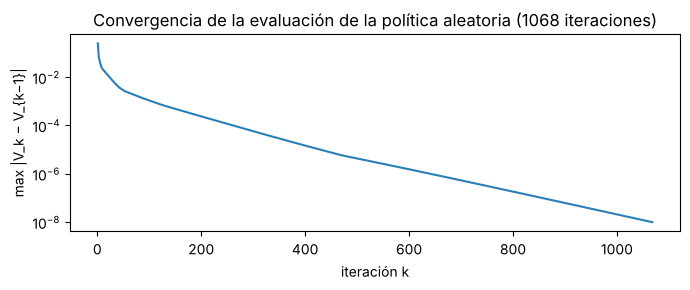

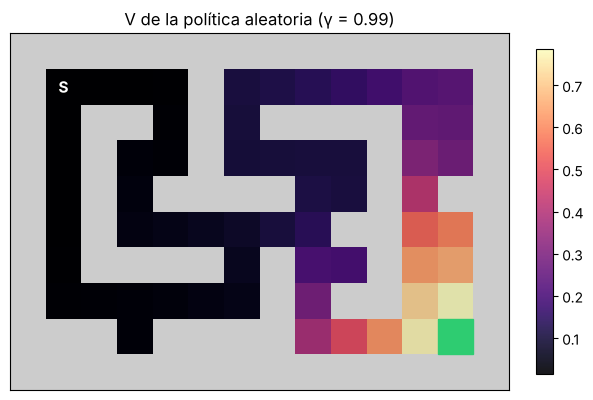

V(S) caminando al azar = 0.0136


In [9]:
deltas = [np.max(np.abs(hist[k + 1] - hist[k])) for k in range(len(hist) - 1)]
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(range(1, len(deltas) + 1), deltas, color="#2980b9")
ax.set_xlabel("iteración k"); ax.set_ylabel("max |V_k − V_{k−1}|")
ax.set_title(f"Convergencia de la evaluación de la política aleatoria ({len(deltas)} iteraciones)")
plt.tight_layout(); plt.show()

plot_cave(env, values=V_rand, title="V de la política aleatoria (γ = 0.99)"); plt.show()
print(f"V(S) caminando al azar = {V_rand[env.start]:.4f}")

Caminar al azar vale casi nada desde S ($\approx 0.013$): el valor está concentrado cerca de la salida. Es la versión cuantitativa de lo que vimos jugando: un agente perdido casi nunca sale.

## Paso 4 — Iteración de valores: la mejor política

Ahora no queremos evaluar *una* política sino encontrar **la mejor**. Cambio mínimo: en vez de promediar sobre las acciones, nos quedamos con **la mejor acción**. Miremos cómo crece $V$ en las iteraciones 1, 5, 10 y al final.

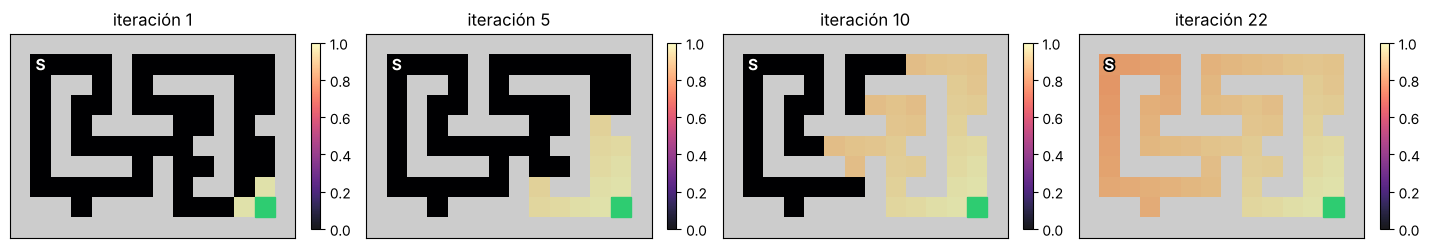

Iteraciones de value iteration: 22


In [10]:
V_star, pi_star, hist_vi = value_iteration(env, gamma)
ks = [1, 5, 10, len(hist_vi) - 1]
plot_row(env, [hist_vi[k] for k in ks], [f"iteración {k}" for k in ks], size=3.6)
print("Iteraciones de value iteration:", len(hist_vi) - 1)

El frente de valor avanza igual que antes, pero ahora con valores mucho más altos: ya no "se diluye" en caminos al azar. Es la **ecuación de Bellman de optimalidad**:

$$V_{k+1}(s) = \max_a \Big[R(s,a) + \gamma \sum_{s'} P(s' \mid s,a)\, V_k(s')\Big]$$

Con $V^*$ en la mano, la política óptima es **greedy**: en cada casilla, la flecha que apunta a la vecina de mayor valor. Dibujemos $V^*$, las flechas y la trayectoria que sigue el agente desde S.

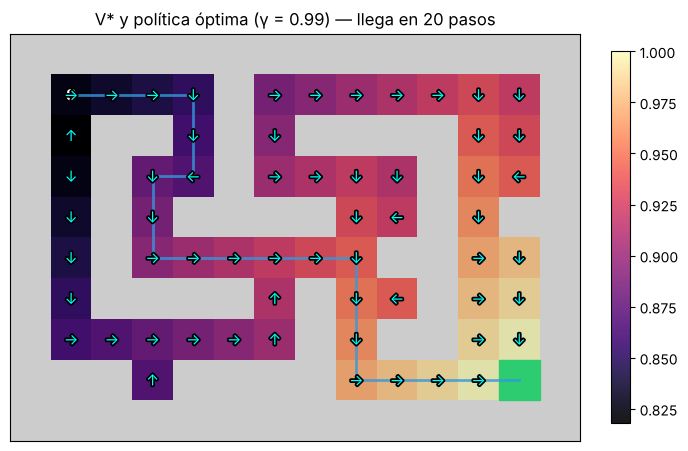

V*(S) = 0.8262   (= 0.99^19 = 0.8262: llega en 20 pasos)


In [11]:
path = run_policy(env, pi_star)
fig, ax = plt.subplots(figsize=(8, 6))
plot_cave(env, values=V_star, policy=pi_star, path=path, ax=ax,
         title=f"V* y política óptima (γ = {gamma}) — llega en {len(path) - 1} pasos")
plt.show()
print(f"V*(S) = {V_star[env.start]:.4f}   (= 0.99^19 = {0.99**19:.4f}: llega en 20 pasos)")

## Paso 5 — Iteración de políticas: evaluar, mejorar, repetir

Otra receta para llegar a la misma política óptima:

1. **Evaluar** la política actual exactamente ($V^\pi$, resolviendo el sistema lineal de Bellman).
2. **Mejorar**: en cada casilla, elegir la acción greedy respecto de $V^\pi$:  $\pi'(s) = \arg\max_a \big[R(s,a) + \gamma \sum_{s'} P(s'|s,a)V^\pi(s')\big]$.
3. Repetir hasta que la política no cambie.

Comparemos con value iteration: después de cada iteración, ¿en qué fracción de casillas la flecha ya es óptima?

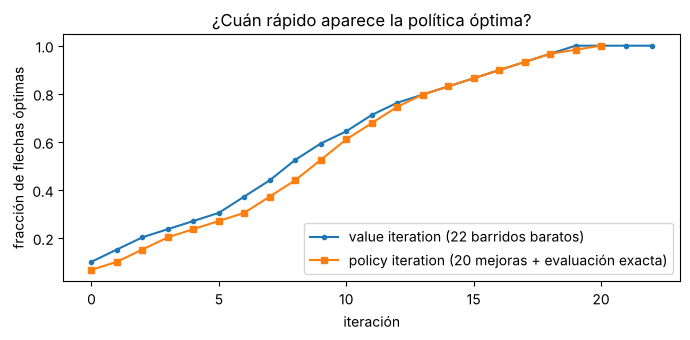

¿Misma política final? True
max |V_PI − V*| = 0.0


In [12]:
V_pi, pi_pi, policies = policy_iteration(env, gamma)
opt = optimal_actions(env, gamma)

frac_vi = [frac_optimal(env, bellman_backup(env, V, gamma).argmax(axis=1), opt) for V in hist_vi]
frac_pi = [frac_optimal(env, p, opt) for p in policies]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(frac_vi, "-o", ms=3, label=f"value iteration ({len(hist_vi) - 1} barridos baratos)")
ax.plot(frac_pi, "-s", ms=4, label=f"policy iteration ({len(policies) - 1} mejoras + evaluación exacta)")
ax.set_xlabel("iteración"); ax.set_ylabel("fracción de flechas óptimas")
ax.set_title("¿Cuán rápido aparece la política óptima?"); ax.legend()
plt.tight_layout(); plt.show()

print("¿Misma política final?", all(opt[s, pi_pi[s]] for s in range(env.nS)))
print("max |V_PI − V*| =", np.max(np.abs(V_pi - V_star)))

Las dos llegan a la misma política y al mismo $V^*$. En esta cueva hacen falta casi la misma cantidad de vueltas (~20) por una razón geométrica: es un **laberinto de pasillos**, y la información de "por acá se sale" viaja **una casilla por vuelta** en ambos métodos. La diferencia está en el **costo** de cada vuelta:

| | cada iteración | iteraciones acá |
|---|---|---|
| Value iteration | un barrido de Bellman (barato) | ~22 |
| Policy iteration | evaluación completa (un sistema lineal) + mejora | ~20 |

En problemas con muchos caminos alternativos, policy iteration suele necesitar **muy pocas** mejoras (a veces 3–5), y la política nunca empeora de una vuelta a la otra.

## Paso 6 — Qué cambia si tocamos el mundo

### 6a. El descuento: $\gamma = 0.5$ vs $\gamma = 0.99$

Mismo mapa, mismo +1 en la salida; solo cambia $\gamma$.

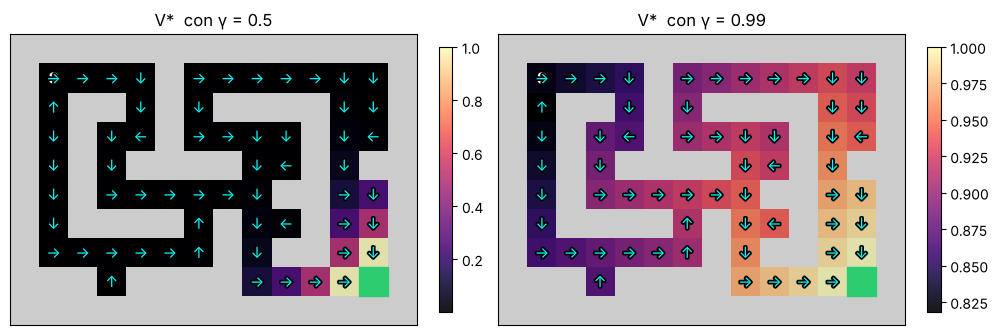

In [13]:
V_05, pi_05, _ = value_iteration(env, 0.5)
V_99, pi_99, _ = value_iteration(env, 0.99)
plot_row(env, [V_05, V_99], ["V*  con γ = 0.5", "V*  con γ = 0.99"],
         policies=[pi_05, pi_99], shared=False, size=5)

Con $\gamma = 0.5$ el mapa de calor queda **negro** salvo al lado de la salida. Las flechas siguen siendo correctas (con el modelo exacto, las diferencias minúsculas alcanzan), pero miremos los números en escala logarítmica, según la distancia a la salida:

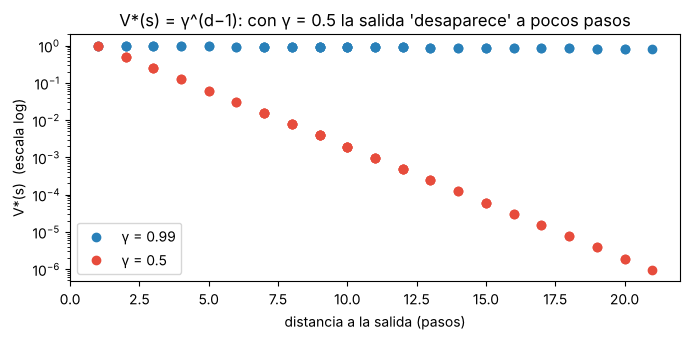

V*(S): γ=0.5 -> 1.91e-06    γ=0.99 -> 0.826


In [14]:
# distancia (en pasos) a la salida siguiendo la política óptima
dist = np.zeros(env.nS, dtype=int)
for s0 in range(env.nS):
    s, d = s0, 0
    while s != env.goal:
        s = int(np.argmax(env.P[s, pi_99[s]])); d += 1
    dist[s0] = d

fig, ax = plt.subplots(figsize=(7, 3.5))
mask = np.arange(env.nS) != env.goal
ax.semilogy(dist[mask], V_99[mask], "o", color="#2980b9", label="γ = 0.99")
ax.semilogy(dist[mask], V_05[mask], "o", color="#e74c3c", label="γ = 0.5")
ax.set_xlabel("distancia a la salida (pasos)"); ax.set_ylabel("V*(s)  (escala log)")
ax.set_title("V*(s) = γ^(d−1): con γ = 0.5 la salida 'desaparece' a pocos pasos")
ax.legend(); plt.tight_layout(); plt.show()
print(f"V*(S): γ=0.5 -> {V_05[env.start]:.2e}    γ=0.99 -> {V_99[env.start]:.3f}")

Desde S, con $\gamma = 0.5$ la salida vale $\approx 2\times10^{-6}$. Con el mapa exacto da igual, pero en la clase 4 vamos a **estimar** estos valores con ruido: ahí una diferencia de $10^{-6}$ se pierde y el agente miope queda perdido lejos de la salida.

### 6b. El costo por paso: `step_reward = -0.01`

¿Por qué el agente óptimo va derecho a la salida en vez de pasear? Con $\gamma < 1$, **llegar antes vale más** ($\gamma^{19} > \gamma^{30}$): el descuento ya lo apura. Para ver el papel del costo por paso, sacamos el descuento ($\gamma = 1$) y comparamos sin costo y con costo de $-0.01$ por paso.

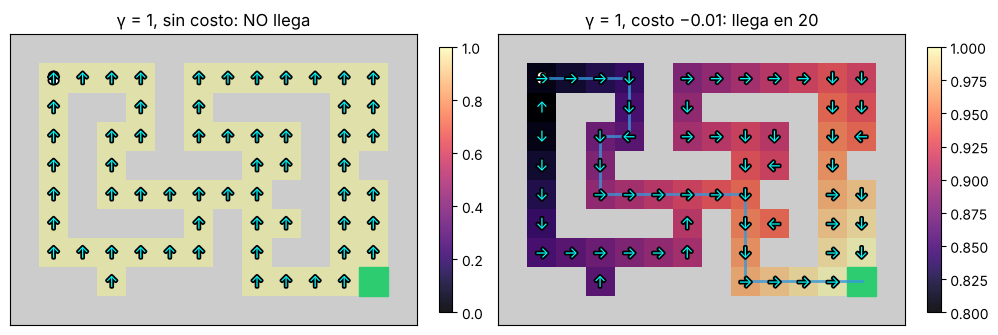

V(S) sin costo: 1.0    con costo: 0.81


In [15]:
env_free = CaveEnv(step_reward=0.0)
env_cost = CaveEnv(step_reward=-0.01)
V_a, pi_a, _ = value_iteration(env_free, 1.0)
V_b, pi_b, _ = value_iteration(env_cost, 1.0)
path_a = run_policy(env_free, pi_a, max_steps=60)
path_b = run_policy(env_cost, pi_b, max_steps=60)
ok = lambda p, e: "llega" if p[-1] == e.goal else "NO llega"
plot_row(env, [V_a, V_b],
         [f"γ = 1, sin costo: {ok(path_a, env_free)}", f"γ = 1, costo −0.01: {ok(path_b, env_cost)} en {len(path_b) - 1}"],
         policies=[pi_a, pi_b], paths=[path_a, path_b], shared=False, size=5)
print("V(S) sin costo:", V_a[env.start], "   con costo:", round(V_b[env.start], 3))

Sin descuento y sin costo, **todas las casillas valen 1**: llegar ahora o en mil pasos da lo mismo, así que todas las acciones empatan y el agente (que en un empate elige ↑) se queda chocando contra la pared de arriba de S para siempre. Con un costo por paso, cada paso extra resta: el valor baja con la distancia y la política vuelve a ser el camino más corto.

**Moraleja:** la recompensa define *qué* queremos; $\gamma$ y el costo por paso definen *con qué apuro*.

### 6c. Piso resbaloso: `slip = 0.2`

Ahora el 20 % de las veces el agente se resbala hacia un costado. ¿Cambia la política óptima?

Casillas donde cambia la flecha óptima: 0


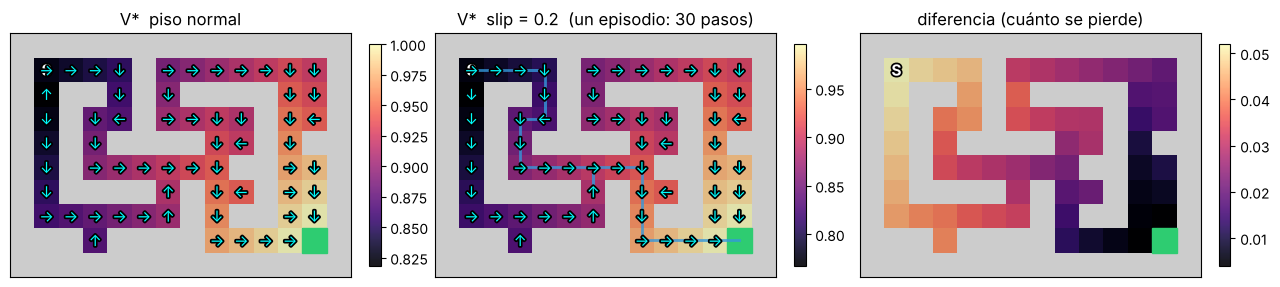

In [16]:
env_slip = CaveEnv(slip=0.2)
V_s, pi_s, hist_s = value_iteration(env_slip, gamma)
opt_det = optimal_actions(env, gamma)
n_diff = sum(not opt_det[s, pi_s[s]] for s in range(env.nS) if s != env.goal)
print("Casillas donde cambia la flecha óptima:", n_diff)

# un episodio con resbalones (de 20 partidas, la más larga)
paths = [run_policy(env_slip, pi_s, max_steps=200, seed=k) for k in range(20)]
p_long = max(paths, key=len)
plot_row(env, [V_star, V_s, V_star - V_s],
         ["V*  piso normal", f"V*  slip = 0.2  (un episodio: {len(p_long) - 1} pasos)", "diferencia (cuánto se pierde)"],
         policies=[pi_star, pi_s, None], paths=[None, p_long, None], shared=False, size=4.3)

En esta cueva **las flechas no cambian**: como no hay pozos ni peligros, resbalarse solo hace perder tiempo (casi siempre contra una pared del pasillo), y la mejor dirección sigue siendo la misma. Lo que cambia es **cuánto vale** cada casilla: más lejos de la salida, más chances de resbalarse en el camino, más pérdida. Veamos cuántos pasos tarda en realidad, jugando 300 veces:

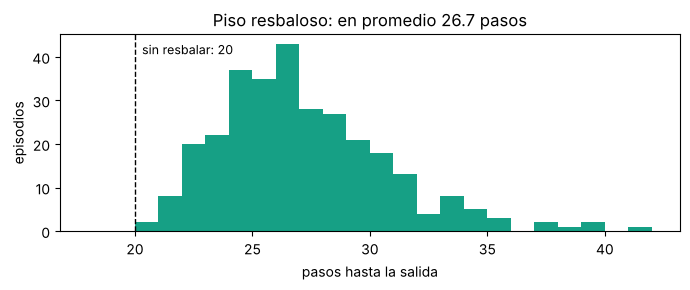

In [17]:
lengths = [len(run_policy(env_slip, pi_s, max_steps=200, seed=k)) - 1 for k in range(300)]
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(lengths, bins=range(18, max(lengths) + 2), color="#16a085")
ax.axvline(20, color="k", ls="--", lw=1); ax.text(20.3, ax.get_ylim()[1] * 0.9, "sin resbalar: 20", fontsize=9)
ax.set_xlabel("pasos hasta la salida"); ax.set_ylabel("episodios")
ax.set_title(f"Piso resbaloso: en promedio {np.mean(lengths):.1f} pasos")
plt.tight_layout(); plt.show()

Observación: con `slip` la política es **la misma**, pero el resultado de cada partida es **aleatorio**. Por eso hablamos de retorno *esperado*: $V^\pi$ es un promedio sobre todas las partidas posibles.

## ✍️ Ejercicio 1 — Cambiar $\gamma$

Cambiá `gamma_ej` (probá 0.7, 0.9, 0.999) y observá: ¿cambia el valor de S? ¿cambian las flechas? ¿cuántas iteraciones necesita value iteration?

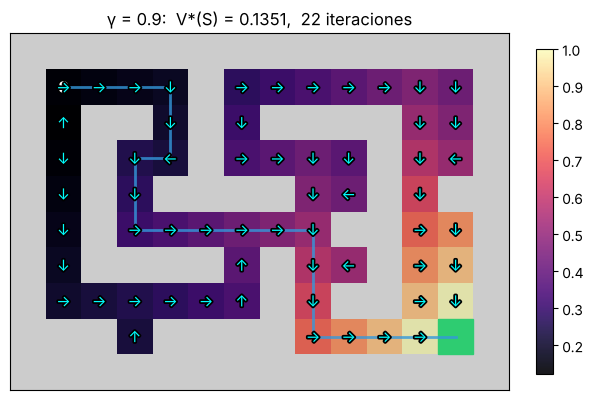

In [18]:
gamma_ej = 0.9   # TODO: probá 0.7, 0.9, 0.999

V_ej, pi_ej, h_ej = value_iteration(env, gamma_ej)
plot_cave(env, values=V_ej, policy=pi_ej, path=run_policy(env, pi_ej),
         title=f"γ = {gamma_ej}:  V*(S) = {V_ej[env.start]:.4f},  {len(h_ej) - 1} iteraciones")
plt.show()

## ✍️ Ejercicio 2 — Piso más resbaloso y paredes que duelen

Cambiá `slip_ej` (probá 0.4, 0.6) y `bump_ej` (castigo por chocar, probá −0.1). ¿Aparece alguna casilla donde la flecha óptima cambie? ¿Qué pasa con $V^*(S)$?

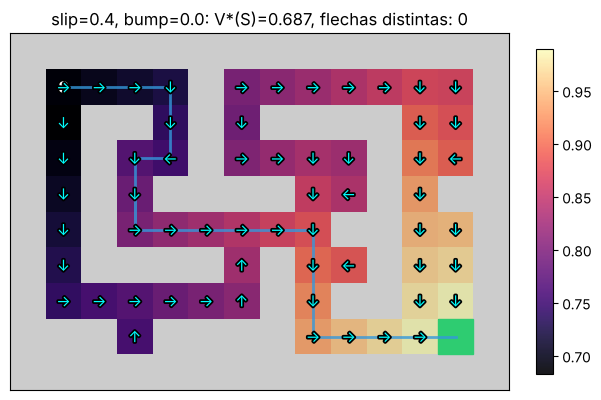

In [19]:
slip_ej = 0.4    # TODO: probá 0.4, 0.6
bump_ej = 0.0    # TODO: probá -0.1

env_ej = CaveEnv(slip=slip_ej, bump_reward=bump_ej)
V_ej, pi_ej, _ = value_iteration(env_ej, gamma)
n_diff = sum(not opt_det[s, pi_ej[s]] for s in range(env.nS) if s != env.goal)
plot_cave(env, values=V_ej, policy=pi_ej, path=run_policy(env_ej, pi_ej, max_steps=200),
         title=f"slip={slip_ej}, bump={bump_ej}: V*(S)={V_ej[env.start]:.3f}, flechas distintas: {n_diff}")
plt.show()

## Preguntas para pensar

1. En el Paso 3 el valor "nace en la salida y se derrama hacia atrás". ¿Qué pasaría si la cueva tuviera **dos** salidas, una con +1 cerca y otra con +10 lejos? ¿Cómo depende la elección de $\gamma$?
2. Todo lo de hoy usó `env.P` y `env.R`. En el juego, el jugador **no** tiene el mapa. ¿Qué información sí tiene después de cada paso, y cómo podría usarla para estimar $V$?
3. Value iteration toca **todas** las casillas en cada barrido. ¿Es razonable eso en un problema con $10^{20}$ estados (por ejemplo, posiciones de ajedrez o frases posibles)?

## Próxima clase

Le sacamos el mapa al agente: solo puede **jugar y anotar** lo que le pasa. En vez de calcular Bellman exacto con $P$ y $R$, va a promediar experiencias ruidosas (Monte Carlo, TD, Q-learning). Es la misma idea que pasar del gradiente exacto sobre todo el dataset al **descenso por gradiente estocástico** con mini-batches que usan para entrenar redes neuronales.